<a href="https://colab.research.google.com/github/houmanhaghi/Gold3nMind/blob/main/3-Coin2Bullion/Coin2Bullion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔰 Descriptions of Project

As you may know, the price of gold (Au) and its derivations is not stable and too many events and news can effect it. One of the most popular actions is to increase the amount of gold in gram not in cose. This goal can be acheived by changing it to its different derivations but in perticular and appropriate time.

# ✅ Definition of Done

The purpose of this project is to forecast the best time of converting gold coin (Emami coin) to bullion and againts actions.

I want to use the history of prices and using bubble formulas to gain this golden times.


## Data collecting


In [1]:
! pip install persiantools

In [2]:
import os
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from persiantools.jdatetime import JalaliDate
from datetime import timedelta
from datetime import datetime, timedelta

calling API — only once — or use from downloaded csv files

website: ```https://www.navasan.tech/```


Telegram Bot: (Free API) ```https://t.me/navasan_contact_bot
```

In [3]:

MODE = 'STORAGE'      # API / STORAGE

market = dict()

items = [
    'xau',          # اونس طلا
    'usd_xau',      # اونس جهانی طلا
    'sekkeh',       # سکه امامی
    'bahar',        # سکه بهار آزادی
    'nim',          # نیم سکه
    'rob',          # ربع سکه
    'gerami',       # سکه گرمی
    'abshodeh',     # مثقال طلای آبشده
    '18ayar',       # گرم طلای 18 عیار
    'bub_18ayar',   # حباب طلای 18
    'bub_abshodeh', # حباب مثقال طلای آبشده
    'bub_bahar',    # حباب سکه بهار آزادی
    'bub_gerami',   # حباب سکه گرمی
    'bub_nim',      # حباب نیم سکه
    'bub_rob',      # حباب ربع سکه
    'bub_sekkeh',   # حباب سکه امامی

]


for item in items:
  if MODE == 'API':
    API_KEY = "freeAOjTDjWzkIwGioUijVGW2Xq0ZyBd"
    Start_Day = "1397-01-01"
    today = JalaliDate.today().strftime("%Y-%m-%d")

    if not os.path.exists('data'):
      os.makedirs('data')

    url = f"https://api.navasan.tech/ohlcSearch/?api_key={API_KEY}&item={item}&start={Start_Day}&end={today}"
    response = requests.get(url)
    print(f"Status Code for {item}: {response.status_code}")
    if response.status_code == 200:
      try:
        data = response.json()
        df = pd.DataFrame(data)
        market[item] = df
        df.to_csv(f"data/{item}.csv", index=False)
        print(f"{item} data saved successfully.")

      except requests.exceptions.JSONDecodeError:
        print(f"Could not decode JSON for {item}. Response text: {response.text}")

      except Exception as e:
        print(f"An error occurred while processing {item}: {e}")


  elif MODE == 'STORAGE':
    csv_path = f"data/{item}.csv"
    if os.path.exists(csv_path):
      try:
        df = pd.read_csv(csv_path)
        market[item] = df
        print(f"{item} data loaded successfully.")

      except Exception as e:
        print(f"An error occurred while loading {item} data: {e}")
    else:
      print(f"{item} data not found.")




xau data not found.
usd_xau data not found.
sekkeh data loaded successfully.
bahar data not found.
nim data not found.
rob data not found.
gerami data not found.
abshodeh data not found.
18ayar data loaded successfully.
bub_18ayar data not found.
bub_abshodeh data not found.
bub_bahar data not found.
bub_gerami data not found.
bub_nim data not found.
bub_rob data not found.
bub_sekkeh data not found.


## Data Cleaning

Prices are in Dollar or Toman

In [4]:
original_market = market.copy()



def j2g(jdate_str: str):
    # expects "YYYY-MM-DD" (Jalali); returns pandas Timestamp
    try:
        y, m, d = map(int, [jdate_str[:4], jdate_str[5:7], jdate_str[8:10]])
        g = JalaliDate(y, m, d).to_gregorian()
        return pd.to_datetime(g)
    except Exception:
        return pd.NaT

for name, df in list(market.items()):
    # drop missing columns quietly; keep first occurrence per 'date'
    df = df.drop(columns=['timestamp', 'open', 'high', 'low'], errors='ignore')
    df = df.drop_duplicates(subset='date', keep='first').sort_values('date').reset_index(drop=True)

    # add Gregorian date
    if 'date' in df.columns:
        df['gregorian_date'] = df['date'].astype(str).apply(j2g)
        df = df[['close',  'date', 'gregorian_date']]
    else:
        df = df[['close']]


    market[name] = df

    print(f'Name: {name}')
    print(df.tail(1))
    print('\n\n')


Name: sekkeh
          close        date gregorian_date
2290  111600000  1404-07-22     2025-10-14



Name: 18ayar
         close        date gregorian_date
2289  10650770  1404-07-22     2025-10-14





## Golden Mind Logics

Apply different popular ways



In [ ]:
### Validation Variables



### sekke / 18ayar

#### Ploting and Visualization


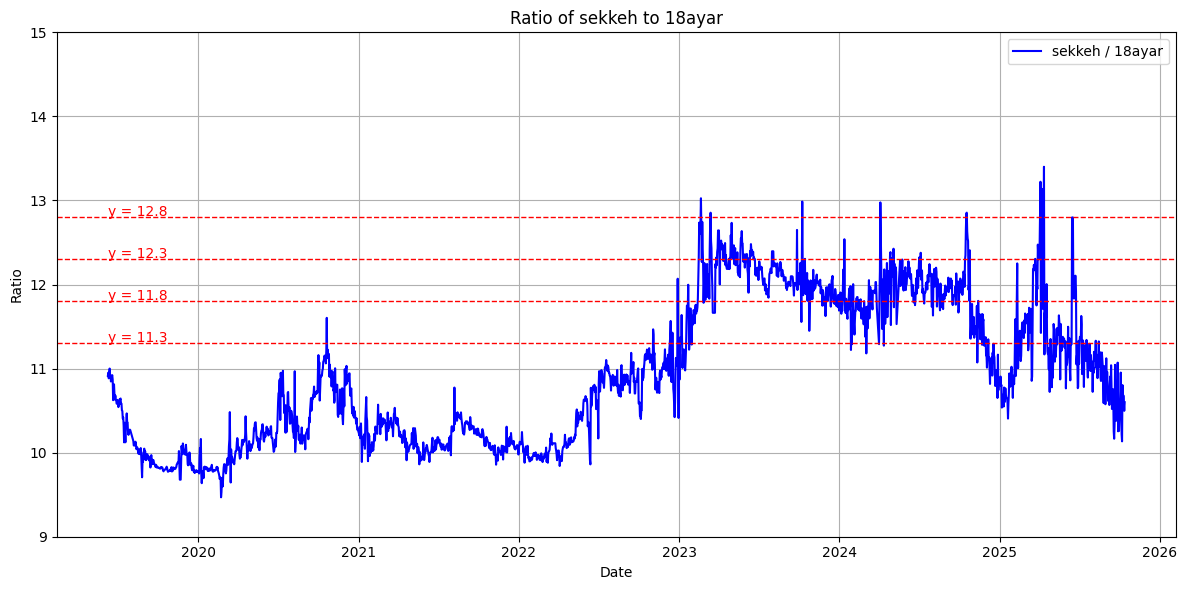

In [6]:
ratio = market['sekkeh']['close'] / market['18ayar']['close']
ratio.index = pd.to_datetime(market['sekkeh']['gregorian_date'])
ratio_df = pd.DataFrame({
    'ratio': ratio
}, index=ratio.index)


plt.figure(figsize=(12, 6))
plt.plot(ratio.index, ratio, label='sekkeh / 18ayar', color='blue')

# Focus on the desired y-range
plt.ylim(9, 15)

# Add the horizontal reference lines
for y in [11.3, 11.8, 12.3, 12.8]:
    plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
    plt.text(ratio.index.min(), y + 0.02, f'y = {y}', color='red')

plt.xlabel('Date')
plt.ylabel('Ratio')
plt.title('Ratio of sekkeh to 18ayar')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



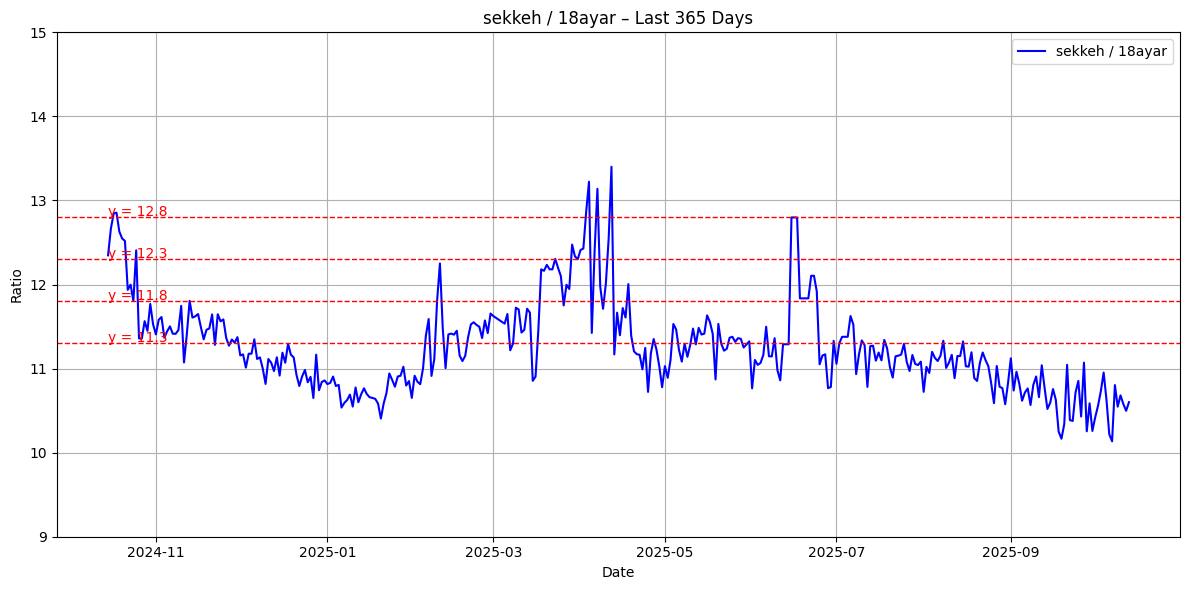

In [7]:
### Last year only

ratio.index = pd.to_datetime(ratio.index)
last_365 = ratio[ratio.index >= (pd.Timestamp.today() - pd.Timedelta(days=365))]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(last_365.index, last_365, label='sekkeh / 18ayar', color='blue')

plt.ylim(9, 15)

# Add guide lines
for y in [11.3, 11.8, 12.3, 12.8]:
    plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
    plt.text(last_365.index.min(), y + 0.02, f'y = {y}', color='red')

plt.xlabel('Date')
plt.ylabel('Ratio')
plt.title('sekkeh / 18ayar – Last 365 Days')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



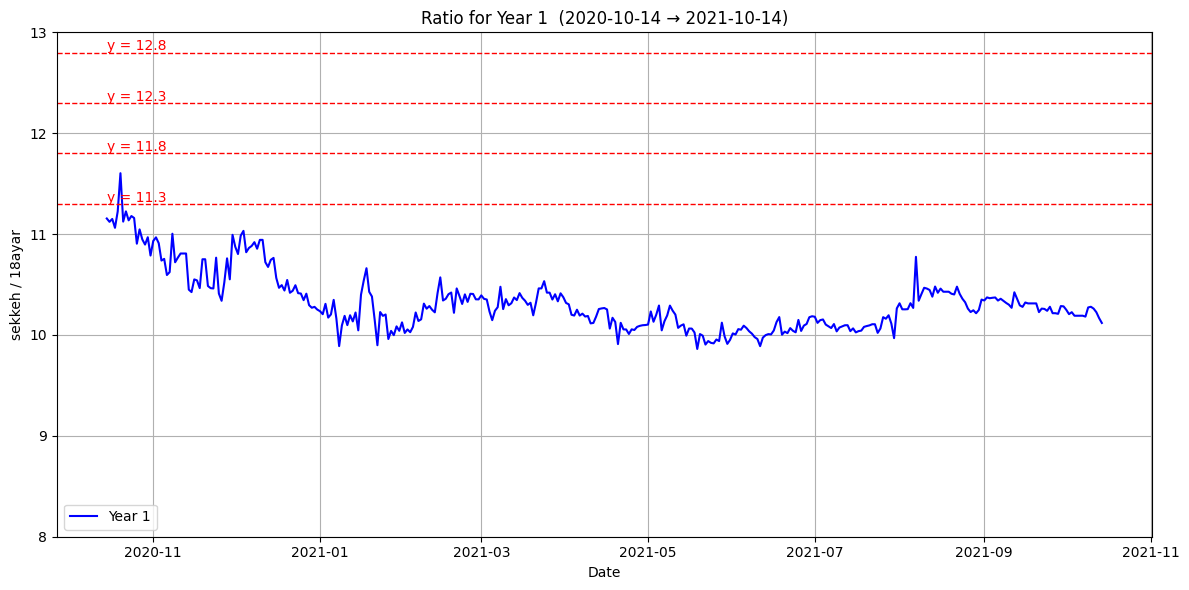

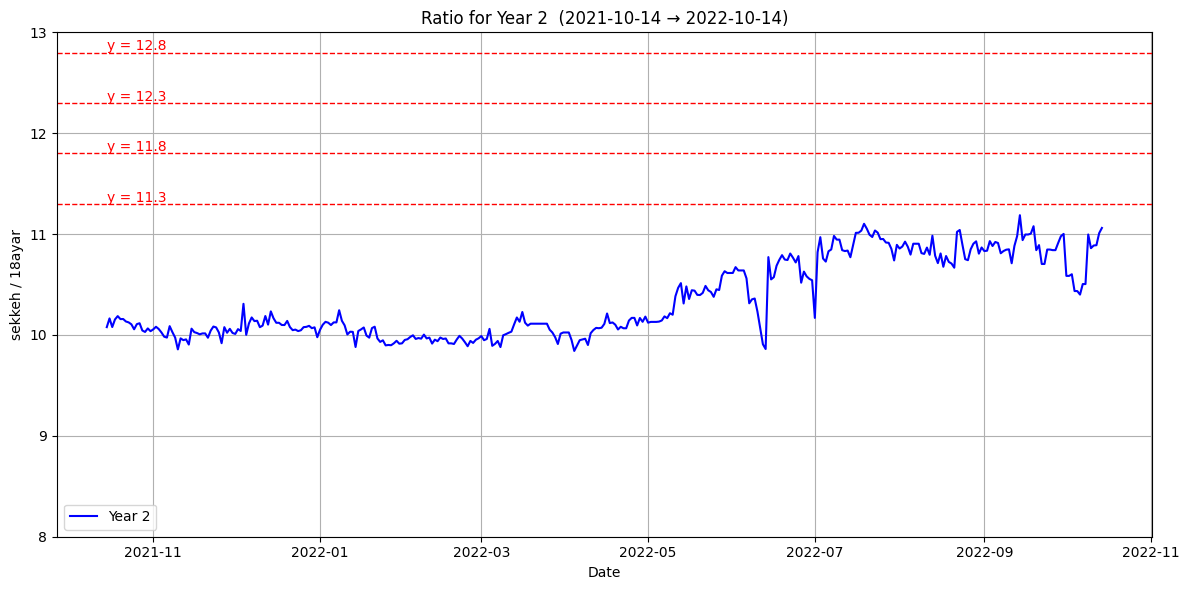

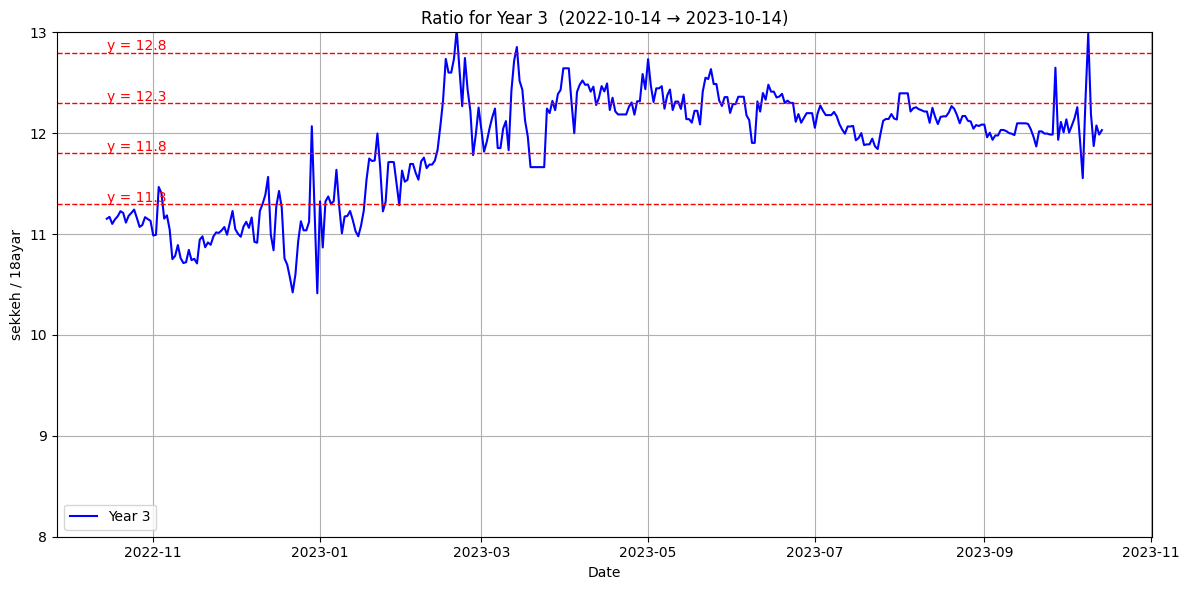

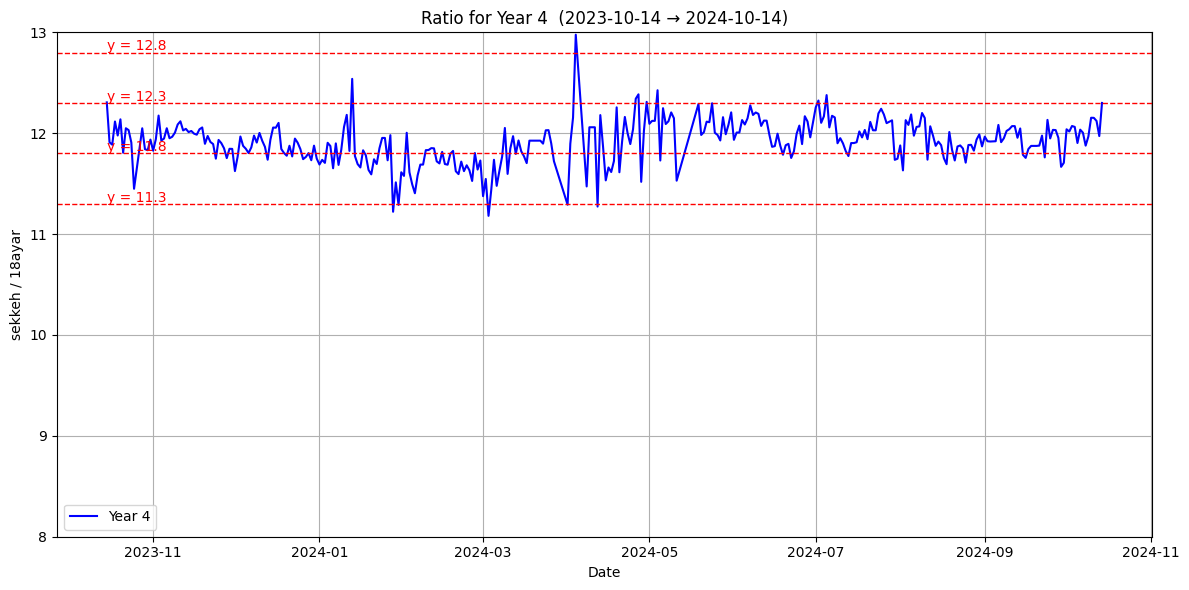

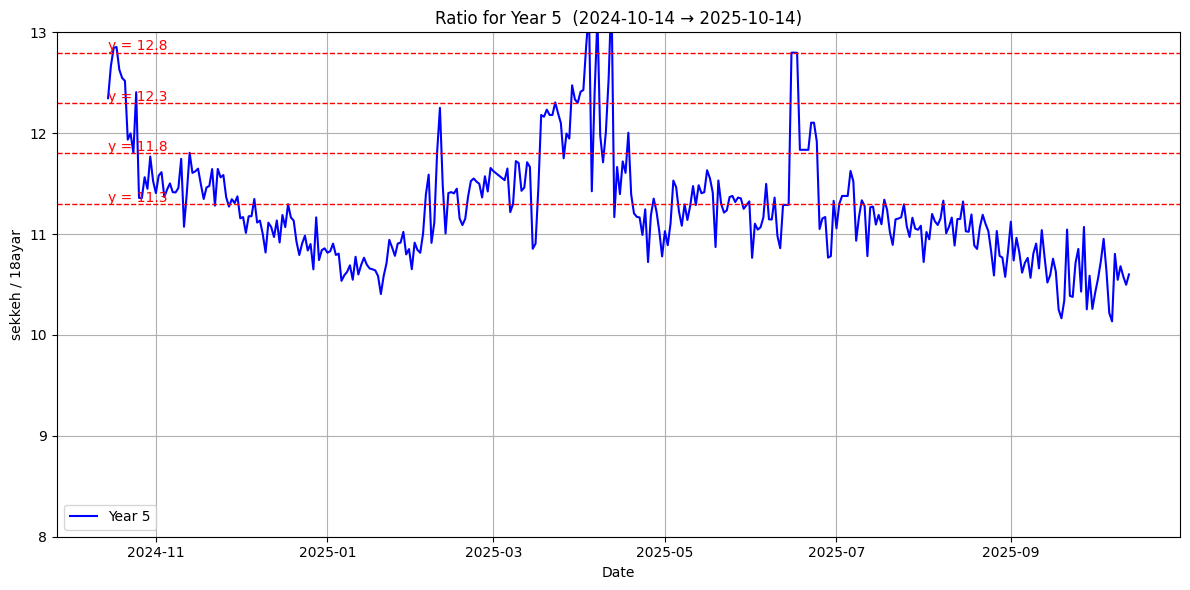

In [8]:
### Last 4 yeares, separeted years

import pandas as pd
import matplotlib.pyplot as plt

# Ensure ratio index is datetime
ratio.index = pd.to_datetime(ratio.index)

today = pd.Timestamp.today()

# Create a list of (start, end) tuples for each 1-year window
periods = [
    (today - pd.DateOffset(years=i+1), today - pd.DateOffset(years=i))
    for i in range(5)
]
periods = periods[::-1]


for i, (start, end) in enumerate(periods, start=1):
    # Filter data for this 1-year window
    window = ratio[(ratio.index >= start) & (ratio.index < end)]

    plt.figure(figsize=(12, 6))
    plt.plot(window.index, window, label=f'Year {i}', color='blue')

    # Focus the y-axis
    plt.ylim(8, 13)

    # Add horizontal guide lines
    for y in [11.3, 11.8, 12.3, 12.8]:
        plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
        plt.text(window.index.min(), y + 0.02, f'y = {y}', color='red')

    plt.xlabel('Date')
    plt.ylabel('sekkeh / 18ayar')
    plt.title(f'Ratio for Year {i}  ({start.date()} → {end.date()})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


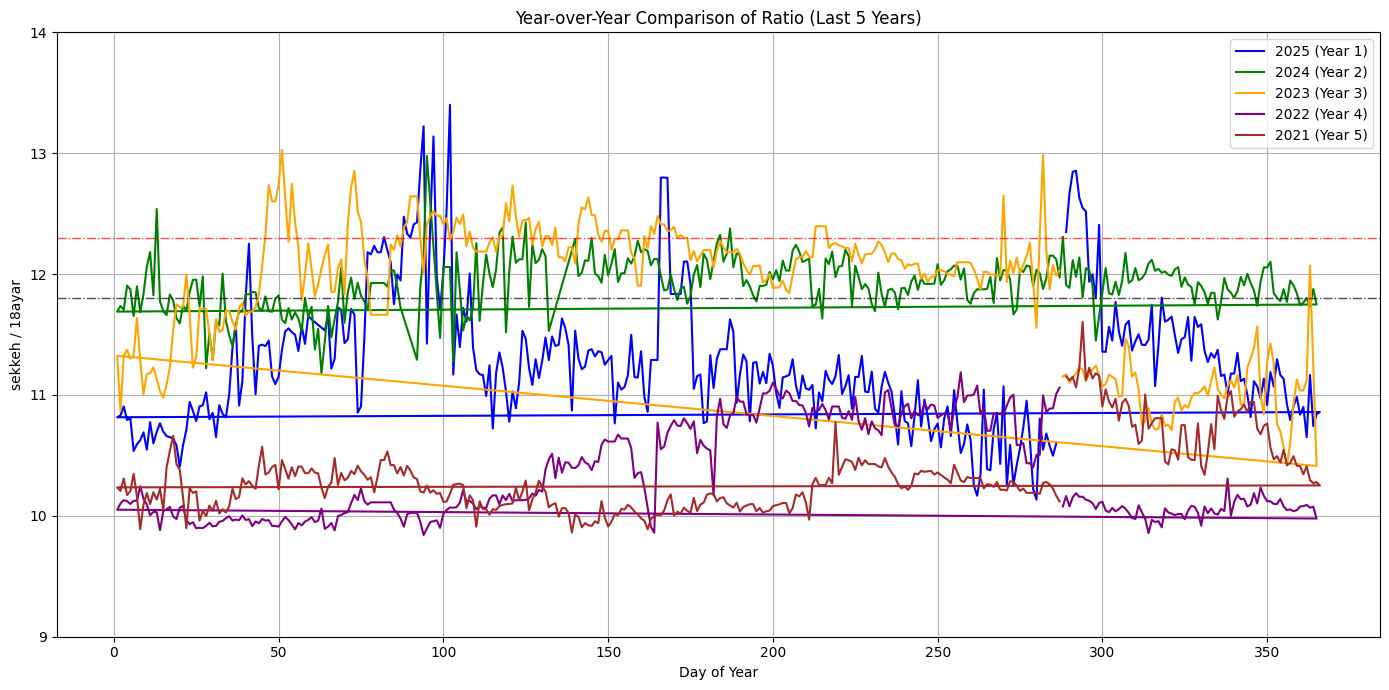

In [9]:
### All last 5 year on one chart

import pandas as pd
import matplotlib.pyplot as plt

# make sure ratio index is datetime
ratio.index = pd.to_datetime(ratio.index)

today = pd.Timestamp.today()

# create 5 one-year periods
periods = [
    (today - pd.DateOffset(years=i+1), today - pd.DateOffset(years=i))
    for i in range(5)
]

colors = ['blue', 'green', 'orange', 'purple', 'brown']

plt.figure(figsize=(14, 7))

for i, ((start, end), color) in enumerate(zip(periods, colors), start=1):
    # slice for that 1-year period
    window = ratio[(ratio.index >= start) & (ratio.index < end)]

    # convert each date to day-of-year
    x = window.index.dayofyear
    y = window.values

    # plot all on same x-axis (day of year)
    plt.plot(x, y, color=color, label=f'{end.year} (Year {i})')

# set y-axis focus
plt.ylim(9, 14)

# add horizontal guide lines
for y_line in [11.8, 12.3]:
    color = 'red' if y_line == 12.3 else 'black'
    plt.axhline(y=y_line, color=color, linestyle='-.', linewidth=1, alpha=0.7)

plt.xlabel('Day of Year')
plt.ylabel('sekkeh / 18ayar')
plt.title('Year-over-Year Comparison of Ratio (Last 5 Years)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



#### Forecasting via LSTM

⚡ Multi-Cutoff Auto-Tuning LSTM Script


=== Retro cutoff: 2025-01-01 ===
→ seq_len=30, horizon=15


   RMSE=0.5825


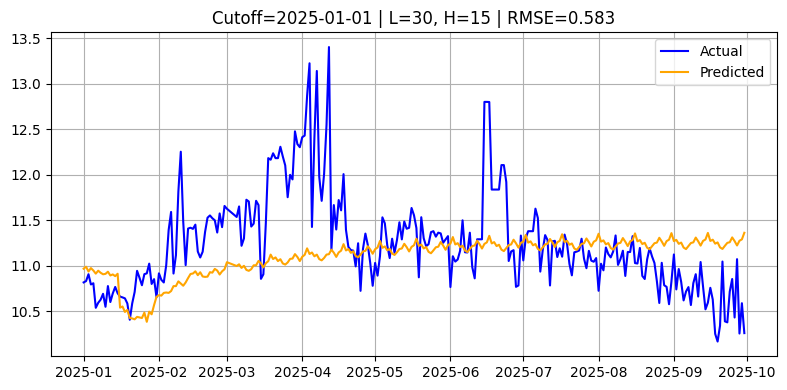

→ seq_len=30, horizon=30


   RMSE=0.8796


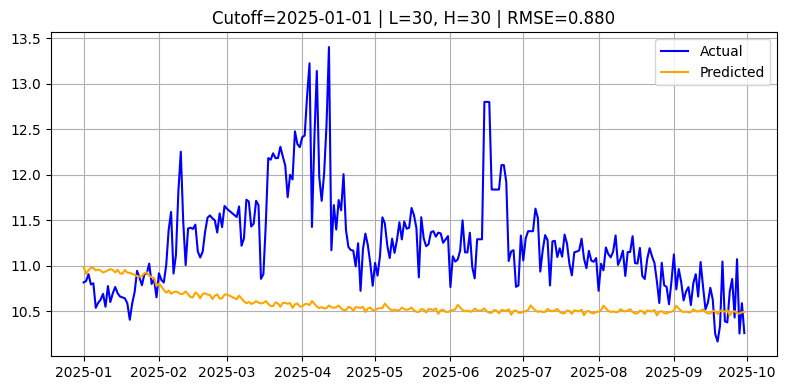

→ seq_len=30, horizon=60


   RMSE=0.7998


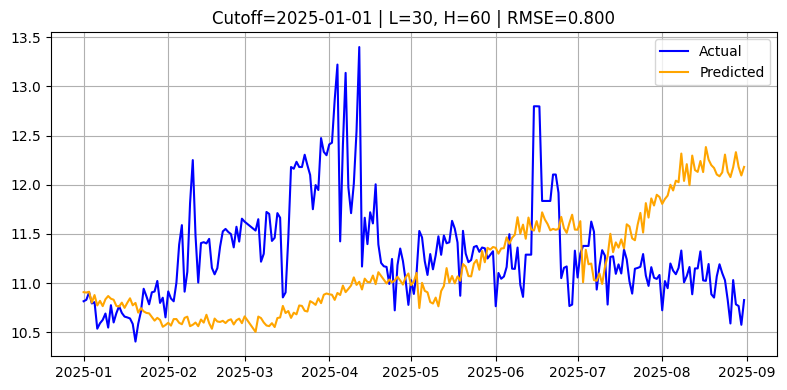

→ seq_len=60, horizon=15


   RMSE=0.9806


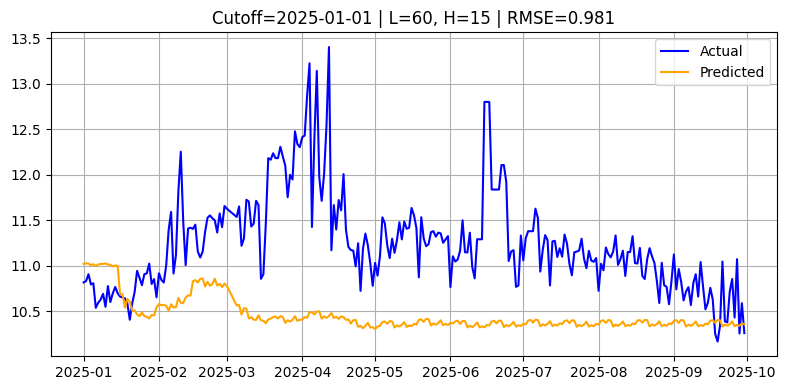

→ seq_len=60, horizon=30


   RMSE=1.1109


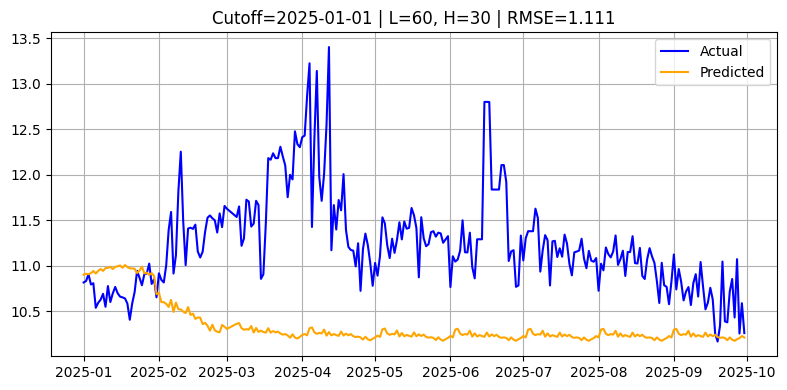

→ seq_len=60, horizon=60


   RMSE=1.1002


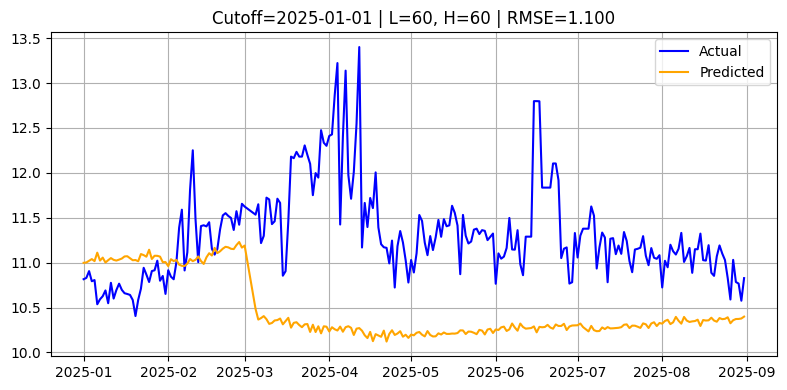

→ seq_len=120, horizon=15


   RMSE=0.7883


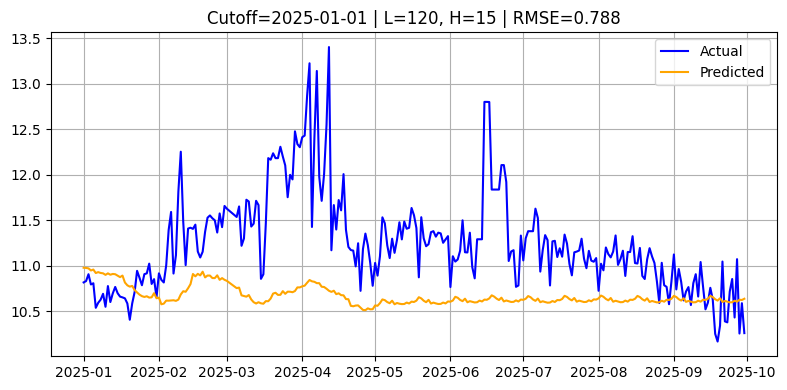

→ seq_len=120, horizon=30


   RMSE=0.9402


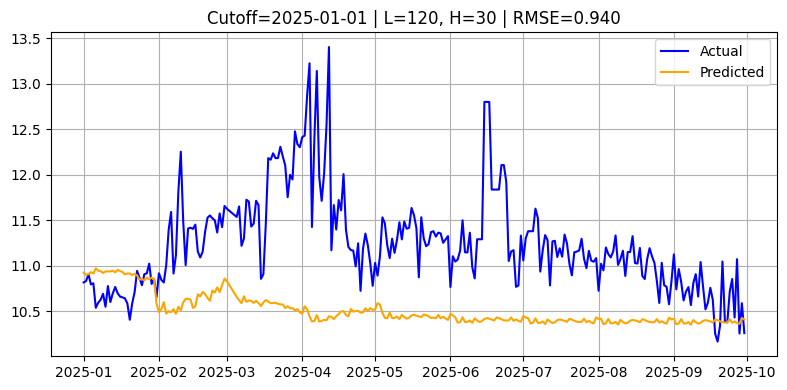

→ seq_len=120, horizon=60


   RMSE=0.9008


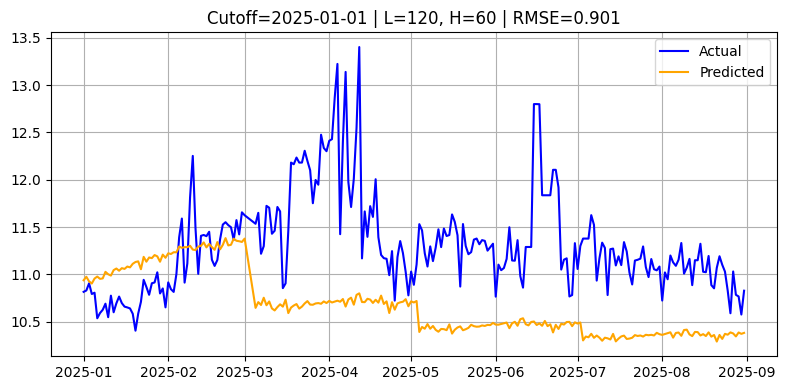

→ seq_len=180, horizon=15


   RMSE=0.9542


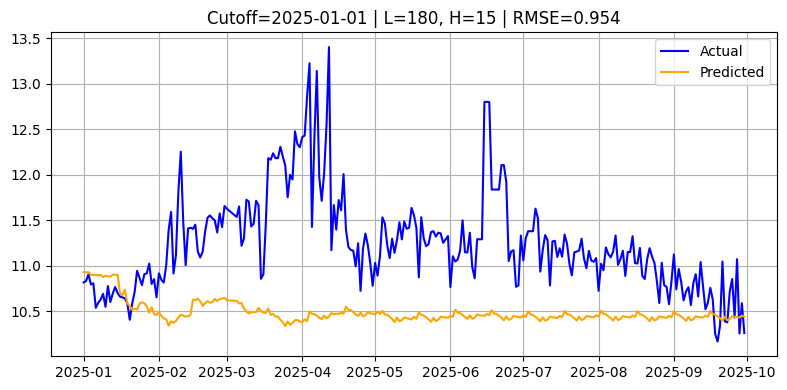

→ seq_len=180, horizon=30


   RMSE=0.8133


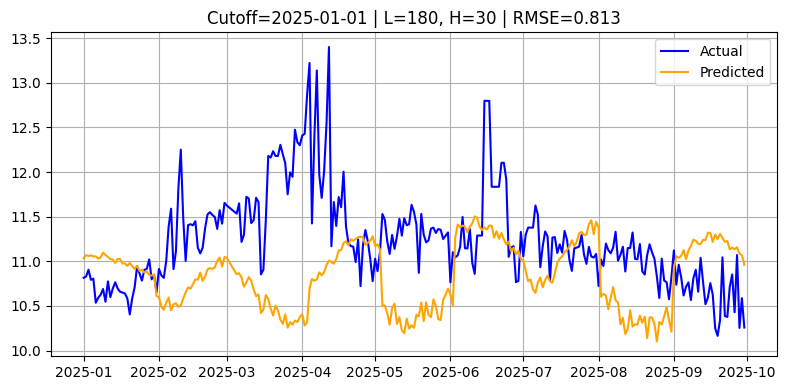

→ seq_len=180, horizon=60


   RMSE=0.7068


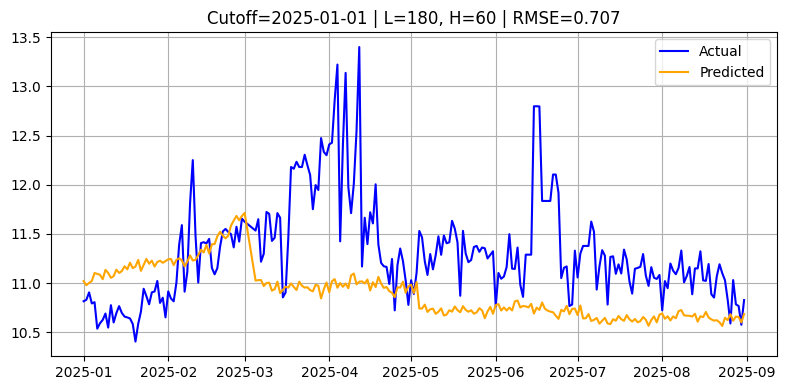


=== Retro cutoff: 2025-04-04 ===
→ seq_len=30, horizon=15


   RMSE=0.7526


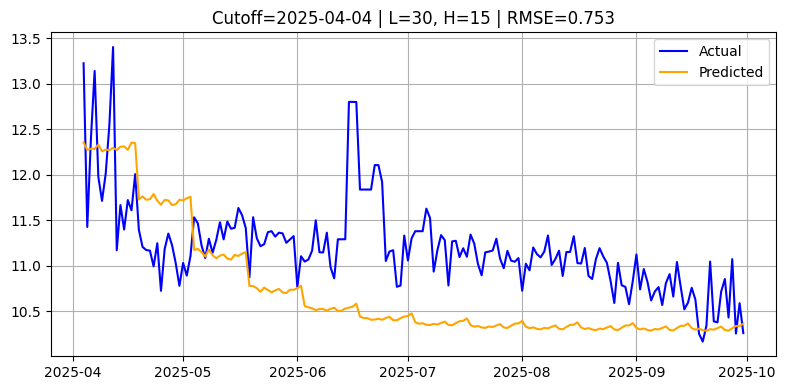

→ seq_len=30, horizon=30


   RMSE=0.7338


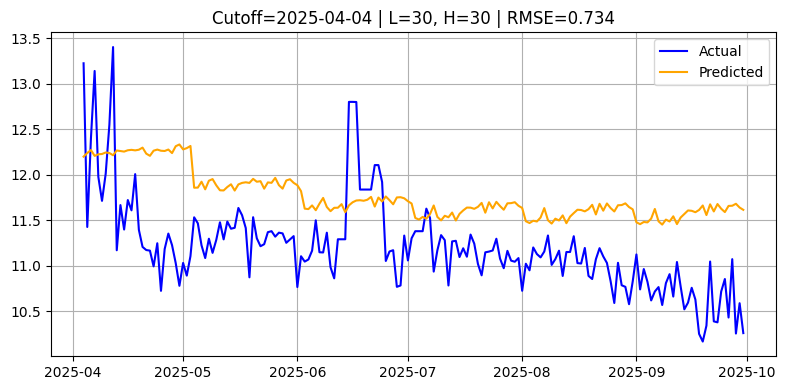

→ seq_len=30, horizon=60


   RMSE=0.6745


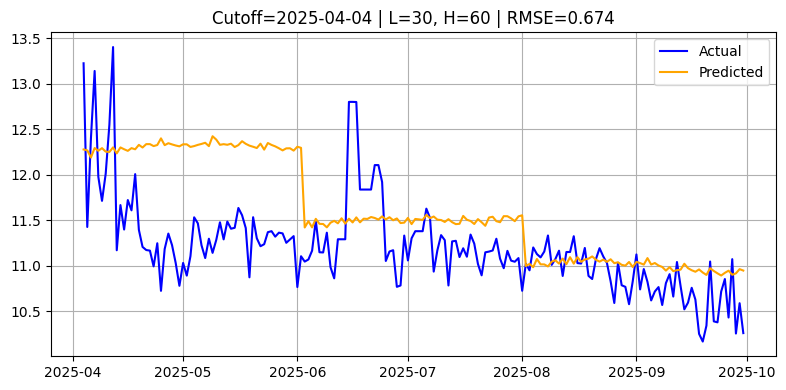

→ seq_len=60, horizon=15


   RMSE=0.9405


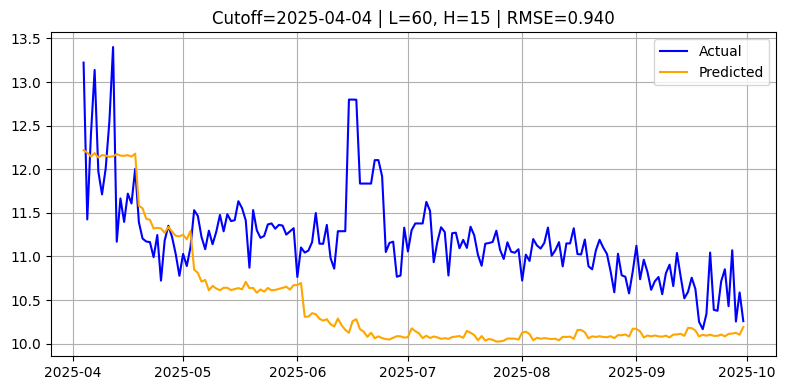

→ seq_len=60, horizon=30


   RMSE=0.6270


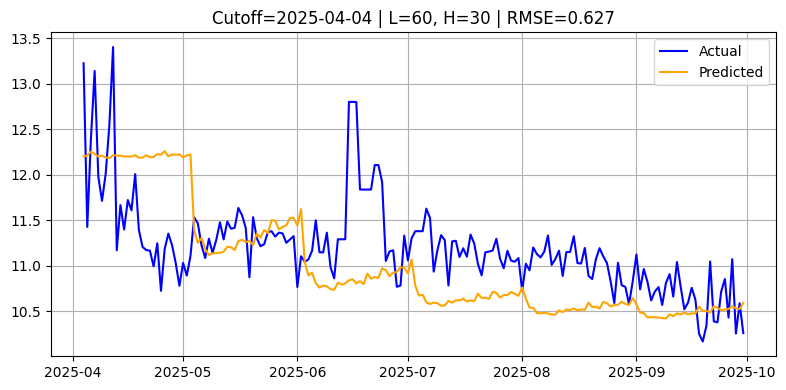

→ seq_len=60, horizon=60


   RMSE=0.6286


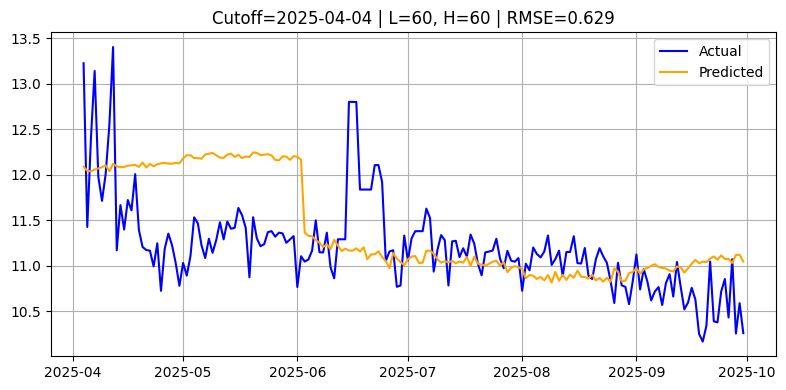

→ seq_len=120, horizon=15


   RMSE=0.5275


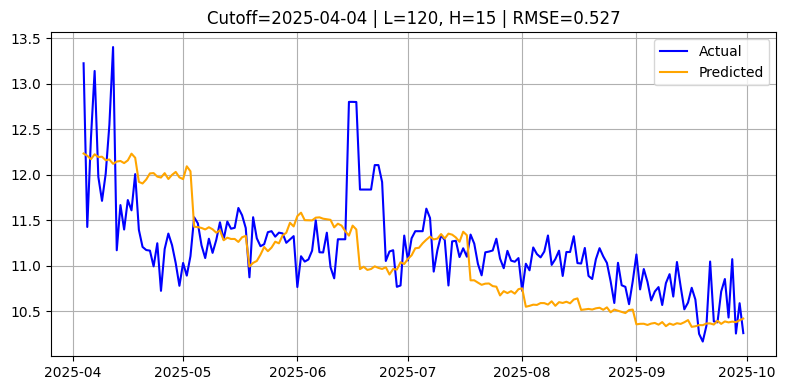

→ seq_len=120, horizon=30


   RMSE=0.5088


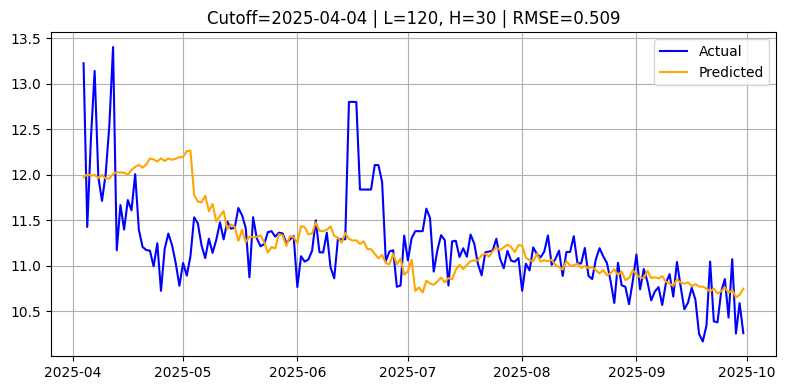

→ seq_len=120, horizon=60


   RMSE=0.6925


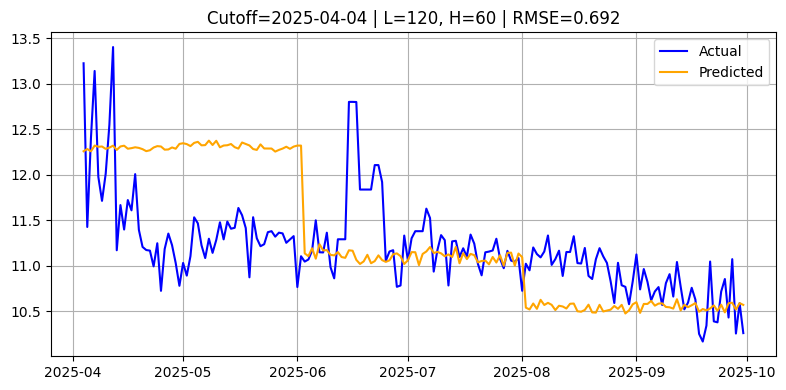

→ seq_len=180, horizon=15


   RMSE=0.4995


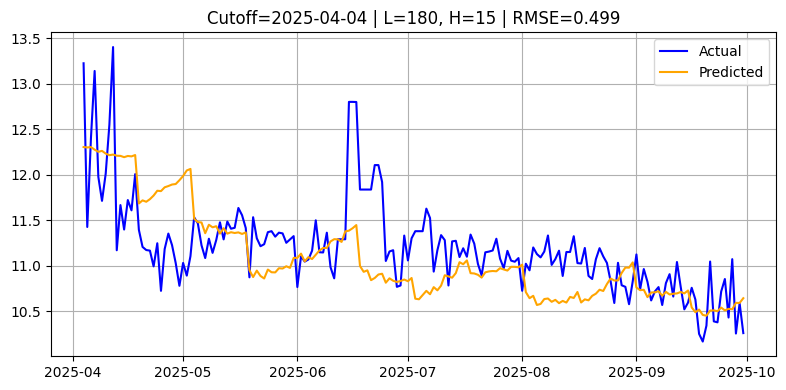

→ seq_len=180, horizon=30


   RMSE=0.5844


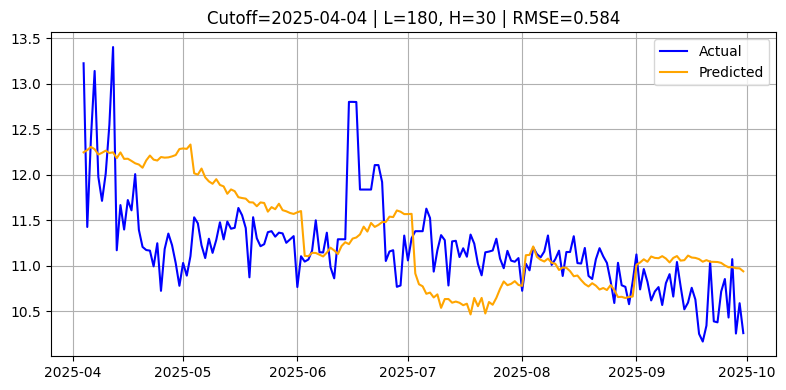

→ seq_len=180, horizon=60


   RMSE=0.6975


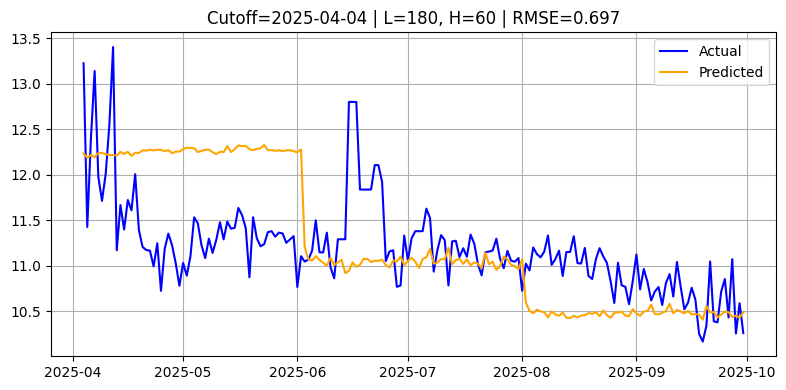


=== Retro cutoff: 2025-07-07 ===
→ seq_len=30, horizon=15


   RMSE=0.3903


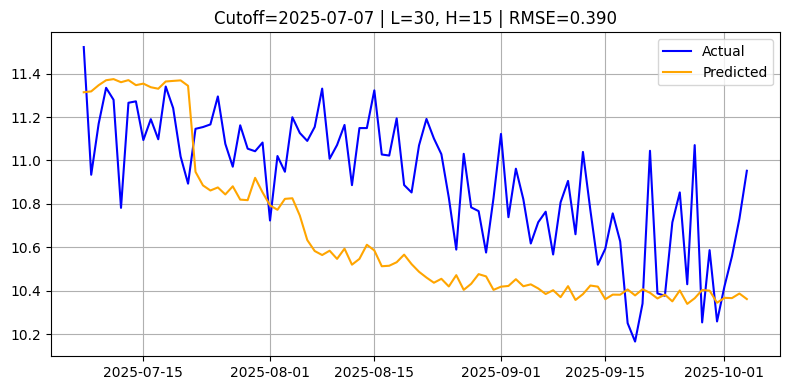

→ seq_len=30, horizon=30


   RMSE=0.2921


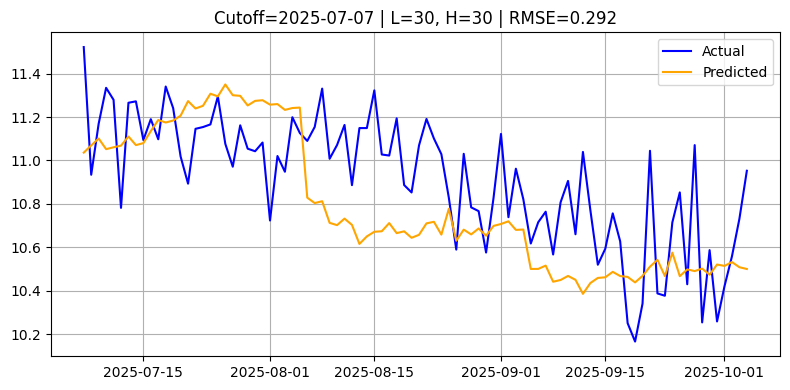

→ seq_len=30, horizon=60


   RMSE=0.4279


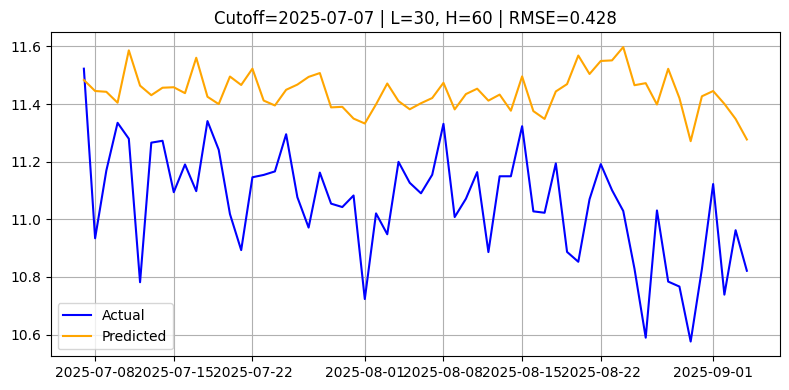

→ seq_len=60, horizon=15


   RMSE=0.3723


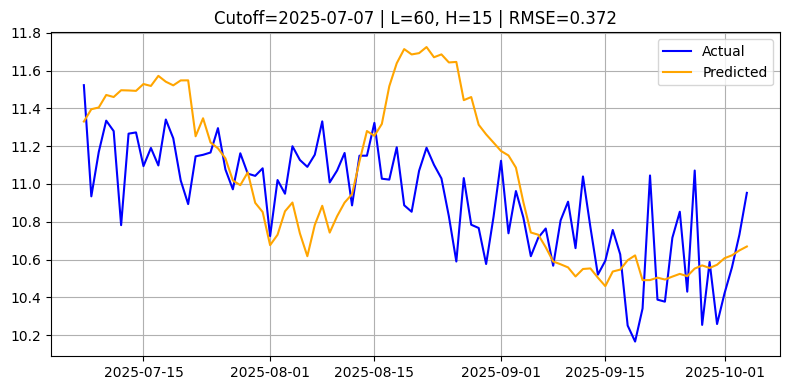

→ seq_len=60, horizon=30


   RMSE=0.4137


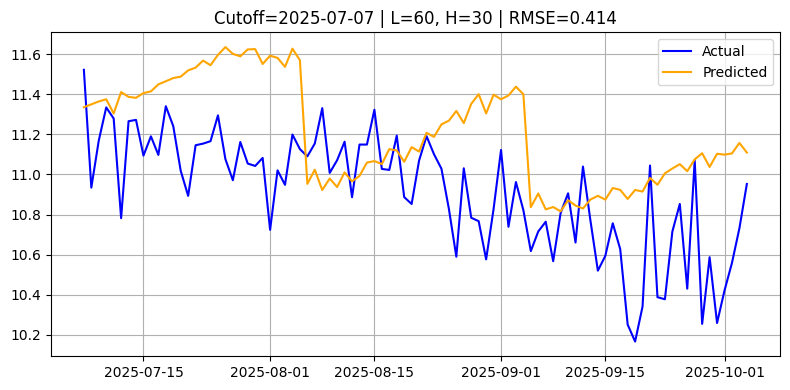

→ seq_len=60, horizon=60


   RMSE=0.5797


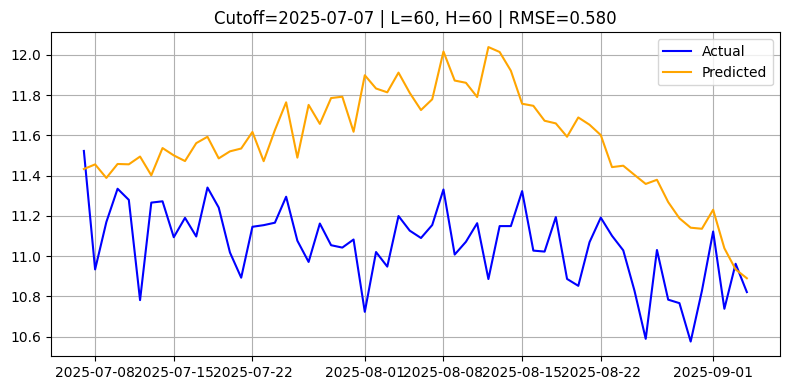

→ seq_len=120, horizon=15


   RMSE=0.3587


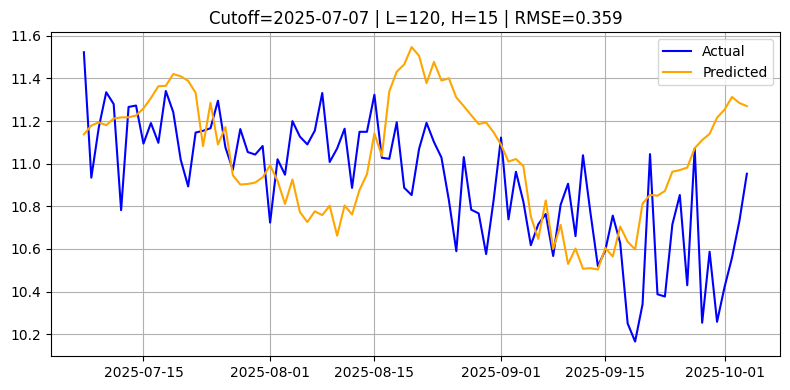

→ seq_len=120, horizon=30


   RMSE=0.3115


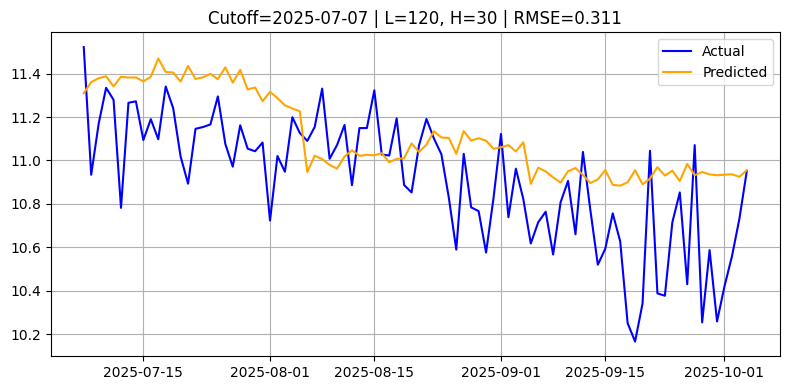

→ seq_len=120, horizon=60


   RMSE=0.6569


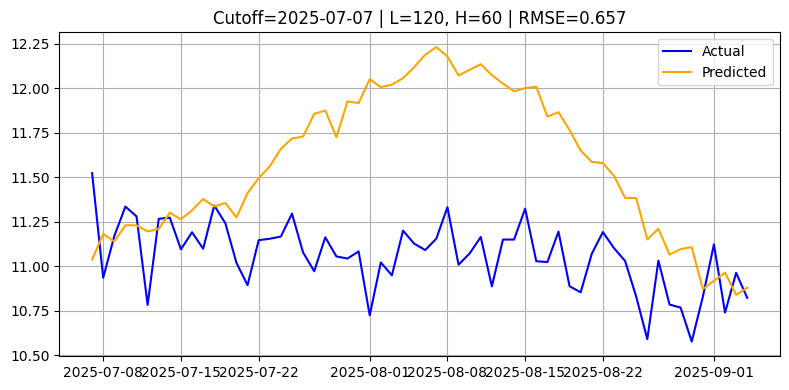

→ seq_len=180, horizon=15


   RMSE=0.7726


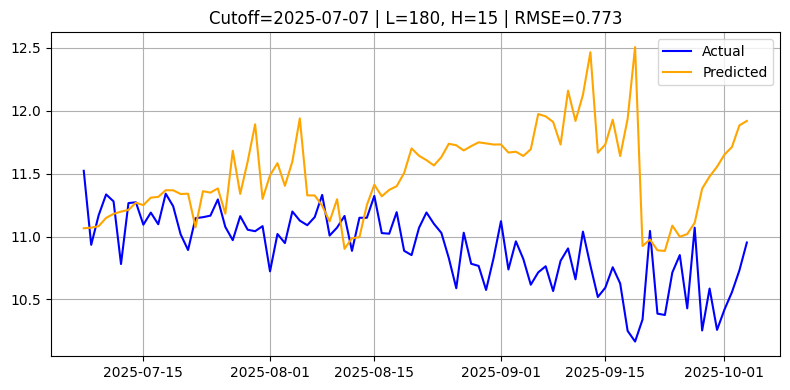

→ seq_len=180, horizon=30


   RMSE=0.3700


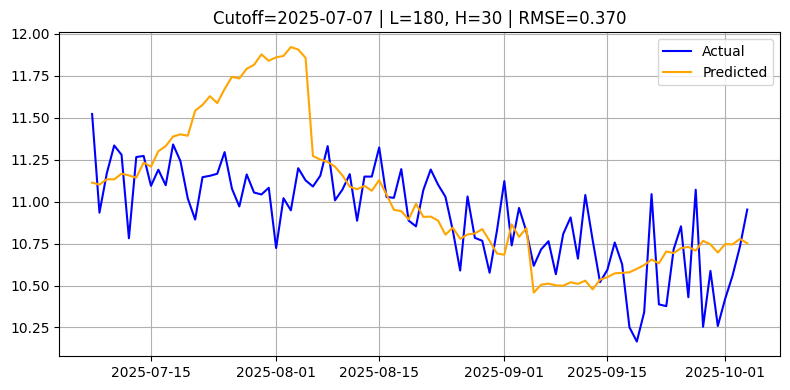

→ seq_len=180, horizon=60


   RMSE=0.3030


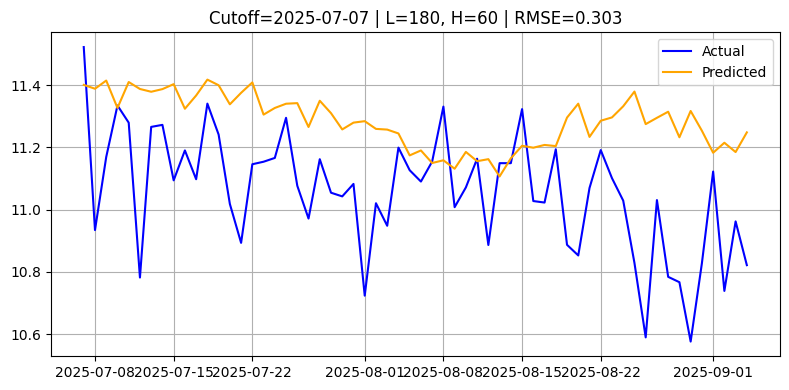


Total training time: 1061.0s

✅ Best average config: L=120, H=15, mean RMSE=0.5582


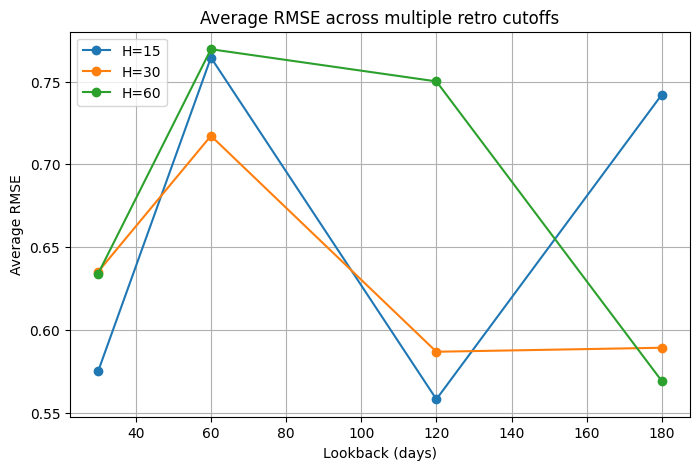

✅ Multi-cutoff tuning complete. Results saved.


In [11]:
# ===========================================================
# Multi-Cutoff Auto-Tuning LSTM Forecast (Improved)
# ===========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import joblib, itertools, time

# ---------------------------------------------------
# 1️⃣ Prepare Data
# ---------------------------------------------------
ratio_df = ratio_df.dropna().copy()
ratio_df['dayofweek'] = ratio_df.index.dayofweek
ratio_df['month'] = ratio_df.index.month
ratio_df['rolling_mean_7'] = ratio_df['ratio'].rolling(7, min_periods=1).mean()
ratio_df['rolling_std_7']  = ratio_df['ratio'].rolling(7, min_periods=1).std().fillna(0)

features = ['ratio', 'dayofweek', 'month', 'rolling_mean_7', 'rolling_std_7']
n_features = len(features)

scaler = MinMaxScaler()
scaled_all = scaler.fit_transform(ratio_df[features])
joblib.dump(scaler, 'scaler_multi_tuned.save')

scaled_df = pd.DataFrame(scaled_all, columns=features, index=ratio_df.index)

# ---------------------------------------------------
# 2️⃣ Helper functions
# ---------------------------------------------------
def create_sequences(data, seq_len, horizon):
    X, y = [], []
    for i in range(len(data) - seq_len - horizon):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len:i + seq_len + horizon, 0])
    return np.array(X), np.array(y)

def build_model(seq_len, n_features, horizon):
    model = Sequential([
        Input(shape=(seq_len, n_features)),
        LSTM(128, return_sequences=True),
        Dropout(0.25),
        LSTM(128, return_sequences=False),
        Dropout(0.25),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def evaluate_model(model, train_data, test_data, seq_len, horizon):
    """Safe evaluation with length checks"""
    if len(train_data) < seq_len:
        return np.array([])  # skip
    last_seq = train_data[-seq_len:]
    preds_scaled = []
    current = last_seq.copy()
    steps = max(1, len(test_data)//horizon)
    for _ in range(steps):
        # ensure reshape fits
        current = current[-seq_len:]
        pred = model.predict(current.reshape(1, seq_len, n_features), verbose=0)[0]
        preds_scaled.extend(pred)
        # append predictions as next window
        new_block = np.column_stack([
            np.array(pred).reshape(-1,1),
            np.zeros((len(pred), n_features-1))
        ])
        current = np.vstack([current[horizon:], new_block])
    preds_df = pd.DataFrame(np.zeros((len(preds_scaled), n_features)), columns=features)
    preds_df['ratio'] = preds_scaled
    preds = scaler.inverse_transform(preds_df)[:,0]
    return preds[:len(test_data)]

# ---------------------------------------------------
# 3️⃣ Parameter grids
# ---------------------------------------------------
lookbacks = [30, 60, 120, 180]
horizons  = [15, 30, 60]
retro_cutoffs = ['2025-01-01', '2025-04-04', '2025-07-07']

results = []
start_all = time.time()

# ---------------------------------------------------
# 4️⃣ Training loop
# ---------------------------------------------------
for retro_cutoff in retro_cutoffs:
    print(f"\n=== Retro cutoff: {retro_cutoff} ===")
    train = scaled_df.loc[:retro_cutoff].values
    test  = scaled_df.loc[retro_cutoff:].values
    test_dates = scaled_df.loc[retro_cutoff:].index

    for seq_len, horizon in itertools.product(lookbacks, horizons):
        print(f"→ seq_len={seq_len}, horizon={horizon}")
        if len(train) < seq_len + horizon:
            print("   Skipped (train too short)")
            continue

        X_train, y_train = create_sequences(train, seq_len, horizon)
        model = build_model(seq_len, n_features, horizon)
        stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)
        model.fit(X_train, y_train, epochs=40, batch_size=32, verbose=0, callbacks=[stop])

        preds = evaluate_model(model, train, test, seq_len, horizon)
        if len(preds) == 0:
            print("   Skipped (not enough test data)")
            continue

        actual = ratio_df.loc[test_dates[:len(preds)], 'ratio'].values
        rmse = np.sqrt(np.mean((preds - actual)**2))
        print(f"   RMSE={rmse:.4f}")
        results.append((retro_cutoff, seq_len, horizon, rmse))
        model.save(f'model_cut{retro_cutoff}_L{seq_len}_H{horizon}.h5')

        # 📈 quick visual
        plt.figure(figsize=(8,4))
        plt.plot(test_dates[:len(preds)], actual, label='Actual', color='blue')
        plt.plot(test_dates[:len(preds)], preds, label='Predicted', color='orange')
        plt.title(f"Cutoff={retro_cutoff} | L={seq_len}, H={horizon} | RMSE={rmse:.3f}")
        plt.legend(); plt.tight_layout(); plt.grid(True)
        plt.show()

print(f"\nTotal training time: {time.time()-start_all:.1f}s")

# ---------------------------------------------------
# 5️⃣ Summarize results
# ---------------------------------------------------
results_df = pd.DataFrame(results, columns=['cutoff','seq_len','horizon','RMSE'])
summary = results_df.groupby(['seq_len','horizon'])['RMSE'].mean().reset_index()
best = summary.loc[summary['RMSE'].idxmin()]
best_seq, best_hor, best_rmse = int(best['seq_len']), int(best['horizon']), best['RMSE']
print(f"\n✅ Best average config: L={best_seq}, H={best_hor}, mean RMSE={best_rmse:.4f}")

summary.to_csv('model_tuning_summary.csv', index=False)

# ---------------------------------------------------
# 6️⃣ RMSE comparison plot
# ---------------------------------------------------
plt.figure(figsize=(8,5))
for horizon in horizons:
    data = summary[summary['horizon']==horizon]
    plt.plot(data['seq_len'], data['RMSE'], marker='o', label=f'H={horizon}')
plt.title("Average RMSE across multiple retro cutoffs")
plt.xlabel("Lookback (days)"); plt.ylabel("Average RMSE")
plt.legend(); plt.grid(True)
plt.show()

print("✅ Multi-cutoff tuning complete. Results saved.")


In [ ]:
# ===========================================================
# Multi-Cutoff Auto-Tuning LSTM Forecast (Improved)
# ===========================================================

# ======================= Parameters ========================
lookbacks = [120, 150, 180, 210, 240]
horizons  = [30, 60, 90]
retro_cutoffs = ['2025-04-04', '2025-07-07', '2025-09-09']
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import joblib, itertools, time

# ---------------------------------------------------
# 1️⃣ Prepare Data
# ---------------------------------------------------
ratio_df = ratio_df.dropna().copy()
ratio_df['dayofweek'] = ratio_df.index.dayofweek
ratio_df['month'] = ratio_df.index.month
ratio_df['rolling_mean_7'] = ratio_df['ratio'].rolling(7, min_periods=1).mean()
ratio_df['rolling_std_7']  = ratio_df['ratio'].rolling(7, min_periods=1).std().fillna(0)

features = ['ratio', 'dayofweek', 'month', 'rolling_mean_7', 'rolling_std_7']
n_features = len(features)

scaler = MinMaxScaler()
scaled_all = scaler.fit_transform(ratio_df[features])
joblib.dump(scaler, 'scaler_multi_tuned.save')

scaled_df = pd.DataFrame(scaled_all, columns=features, index=ratio_df.index)

# ---------------------------------------------------
# 2️⃣ Helper functions
# ---------------------------------------------------
def create_sequences(data, seq_len, horizon):
    X, y = [], []
    for i in range(len(data) - seq_len - horizon):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len:i + seq_len + horizon, 0])
    return np.array(X), np.array(y)

def build_model(seq_len, n_features, horizon):
    model = Sequential([
        Input(shape=(seq_len, n_features)),
        LSTM(128, return_sequences=True),
        Dropout(0.25),
        LSTM(128, return_sequences=False),
        Dropout(0.25),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def evaluate_model(model, train_data, test_data, seq_len, horizon):
    """Safe evaluation with length checks"""
    if len(train_data) < seq_len:
        return np.array([])  # skip
    last_seq = train_data[-seq_len:]
    preds_scaled = []
    current = last_seq.copy()
    steps = max(1, len(test_data)//horizon)
    for _ in range(steps):
        # ensure reshape fits
        current = current[-seq_len:]
        pred = model.predict(current.reshape(1, seq_len, n_features), verbose=0)[0]
        preds_scaled.extend(pred)
        # append predictions as next window
        new_block = np.column_stack([
            np.array(pred).reshape(-1,1),
            np.zeros((len(pred), n_features-1))
        ])
        current = np.vstack([current[horizon:], new_block])
    preds_df = pd.DataFrame(np.zeros((len(preds_scaled), n_features)), columns=features)
    preds_df['ratio'] = preds_scaled
    preds = scaler.inverse_transform(preds_df)[:,0]
    return preds[:len(test_data)]

# ---------------------------------------------------
# 3️⃣ Parameter grids
# ---------------------------------------------------


results = []
start_all = time.time()

# ---------------------------------------------------
# 4️⃣ Training loop
# ---------------------------------------------------
for retro_cutoff in retro_cutoffs:
    print(f"\n=== Retro cutoff: {retro_cutoff} ===")
    train = scaled_df.loc[:retro_cutoff].values
    test  = scaled_df.loc[retro_cutoff:].values
    test_dates = scaled_df.loc[retro_cutoff:].index

    for seq_len, horizon in itertools.product(lookbacks, horizons):
        print(f"→ seq_len={seq_len}, horizon={horizon}")
        if len(train) < seq_len + horizon:
            print("   Skipped (train too short)")
            continue

        X_train, y_train = create_sequences(train, seq_len, horizon)
        model = build_model(seq_len, n_features, horizon)
        stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)
        model.fit(X_train, y_train, epochs=40, batch_size=32, verbose=0, callbacks=[stop])

        preds = evaluate_model(model, train, test, seq_len, horizon)
        if len(preds) == 0:
            print("   Skipped (not enough test data)")
            continue

        actual = ratio_df.loc[test_dates[:len(preds)], 'ratio'].values
        rmse = np.sqrt(np.mean((preds - actual)**2))
        print(f"   RMSE={rmse:.4f}")
        results.append((retro_cutoff, seq_len, horizon, rmse))
        model.save(f'model_cut{retro_cutoff}_L{seq_len}_H{horizon}.h5')

        # 📈 quick visual
        plt.figure(figsize=(8,4))
        plt.plot(test_dates[:len(preds)], actual, label='Actual', color='blue')
        plt.plot(test_dates[:len(preds)], preds, label='Predicted', color='orange')
        plt.title(f"Cutoff={retro_cutoff} | L={seq_len}, H={horizon} | RMSE={rmse:.3f}")
        plt.legend(); plt.tight_layout(); plt.grid(True)
        plt.show()

print(f"\nTotal training time: {time.time()-start_all:.1f}s")

# ---------------------------------------------------
# 5️⃣ Summarize results
# ---------------------------------------------------
results_df = pd.DataFrame(results, columns=['cutoff','seq_len','horizon','RMSE'])
summary = results_df.groupby(['seq_len','horizon'])['RMSE'].mean().reset_index()
best = summary.loc[summary['RMSE'].idxmin()]
best_seq, best_hor, best_rmse = int(best['seq_len']), int(best['horizon']), best['RMSE']
print(f"\n✅ Best average config: L={best_seq}, H={best_hor}, mean RMSE={best_rmse:.4f}")

summary.to_csv('model_tuning_summary.csv', index=False)

# ---------------------------------------------------
# 6️⃣ RMSE comparison plot
# ---------------------------------------------------
plt.figure(figsize=(8,5))
for horizon in horizons:
    data = summary[summary['horizon']==horizon]
    plt.plot(data['seq_len'], data['RMSE'], marker='o', label=f'H={horizon}')
plt.title("Average RMSE across multiple retro cutoffs")
plt.xlabel("Lookback (days)"); plt.ylabel("Average RMSE")
plt.legend(); plt.grid(True)
plt.show()

print("✅ Multi-cutoff tuning complete. Results saved.")


### bubble of sekke and 18ayar

### dollar * ounce